# 08 — Phân tích lỗi HSV12 + KNN bằng ảnh thật

Mục tiêu: giải thích dự đoán của **cấu hình đã khóa**, không sửa mô hình. Đọc kết quả notebook 07, tổng hợp toàn bộ test và xem các trường hợp minh họa. Không quét tham số, không sửa DATA/split, không fit train+dev.

Với k=1, nhãn của ảnh train gần nhất quyết định dự đoán. Ảnh gần nhất có nhãn đúng được hiển thị để đối chiếu, không phải một dự đoán thay thế. Khoảng cách là Euclidean giữa histogram HSV12 đã L2, không phải xác suất đúng.

Test đã được xem trong khảo sát trước. Các ảnh minh họa là ví dụ được chọn có chủ đích, không phải mẫu ngẫu nhiên đại diện cho toàn test.

In [1]:
import json
import hashlib
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.neighbors import KNeighborsClassifier
from IPython.display import display

PROJECT_ROOT = Path(r"C:\CS231")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.preprocessing import read_rgb224
from src.evaluation.value_metrics import evaluate_classification

DATA_ROOT = PROJECT_ROOT / "DATA"
RESULTS_ROOT = PROJECT_ROOT / "src" / "KNN" / "results_224"
TEST_DIR = RESULTS_ROOT / "test_final"
output_dir = RESULTS_ROOT / "error_analysis"
config_file = RESULTS_ROOT / "selection" / "locked_knn_config.json"
config = json.loads(config_file.read_text(encoding="utf-8"))

## 1. Đọc đúng bằng chứng của bước test

Kiểm tra file khóa, train và các output đã dùng. Nếu dự đoán lưu không còn khớp feature/model, dừng trước khi giải thích ảnh. Việc fit KNN bên dưới chỉ nạp train vào bộ tìm hàng xóm, không học thêm từ test.

In [2]:
def file_hash(path):
    with path.open("rb") as file:
        return hashlib.file_digest(file, "sha256").hexdigest()


if config["feature_id"] != "HSV12" or config["knn"]["n_neighbors"] != 1:
    sys.exit("Notebook này dành cho HSV12, k=1 đã khóa.")
if config_file.read_bytes() != (TEST_DIR / "locked_knn_config_used.json").read_bytes():
    sys.exit("Cấu hình hiện tại khác cấu hình đã dùng ở bước test.")
for name, expected in config["sha256"].items():
    path = PROJECT_ROOT / name
    if not path.is_file() or file_hash(path) != expected:
        sys.exit("File đã khóa bị thiếu hoặc thay đổi: " + name)

feature_dir = PROJECT_ROOT / config["feature_folder"]
X_train = np.load(feature_dir / "X_train.npy", mmap_mode="r")
y_train = np.load(feature_dir / "y_train.npy")
train_manifest = pd.read_csv(feature_dir / "train_manifest.csv")
X_test = np.load(TEST_DIR / "X_test.npy", mmap_mode="r")
test_manifest = pd.read_csv(TEST_DIR / "test_manifest.csv")
predictions = pd.read_csv(TEST_DIR / "predictions_test.csv")
y_test = predictions["y_true_vnd"].to_numpy()
y_pred = predictions["y_pred_vnd"].to_numpy()

if not predictions["relative_path"].equals(test_manifest["relative_path"]):
    sys.exit("Thứ tự dự đoán không khớp manifest test.")
if not np.array_equal(y_test, test_manifest["label_vnd"]) or not np.array_equal(y_train, train_manifest["label_vnd"]):
    sys.exit("Nhãn không khớp manifest.")
if X_train.shape != (len(y_train), config["feature_dim"]) or X_test.shape != (len(y_test), config["feature_dim"]):
    sys.exit("Shape feature không khớp nhãn hoặc cấu hình.")

scores = evaluate_classification(y_test, y_pred)
if scores != json.loads((TEST_DIR / "metrics_test.json").read_text(encoding="utf-8")):
    sys.exit("Dự đoán không khớp độ đo đã lưu.")
output_dir.mkdir(parents=True, exist_ok=True)
print("Đúng:", int((y_test == y_pred).sum()), "| Sai:", int((y_test != y_pred).sum()))

Đúng: 1187 | Sai: 366


## 2. Tổng quan toàn bộ lỗi

Recall thấp nghĩa là nhiều ảnh thật của lớp bị nhận thành lớp khác. Precision thấp nghĩa là nhiều ảnh lớp khác bị gọi nhầm thành lớp này. Cặp lỗi được tính theo hai chiều để xem mức nhầm giữa hai mệnh giá; bảng có hướng vẫn được giữ để đánh giá chênh lệch VND.

MAE = tổng chênh lệch / toàn bộ số ảnh test. Không chia chỉ trên ảnh sai; chênh lệch danh nghĩa không phải thiệt hại tài chính thực tế.

In [3]:
per_class = pd.DataFrame(scores["per_class"])
per_class["error_rate"] = per_class["fn"] / per_class["support"]
display(per_class[["denomination_vnd", "support", "fn", "error_rate", "precision", "recall", "f1"]])

cm = np.array(scores["confusion_matrix"])
labels = config["classes_vnd"]
rows = []
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        rows.append({"class_a": labels[i], "class_b": labels[j],
                     "a_to_b": int(cm[i, j]), "b_to_a": int(cm[j, i]),
                     "total_errors": int(cm[i, j] + cm[j, i])})
pairs = pd.DataFrame(rows).sort_values(
    ["total_errors", "class_a", "class_b"], ascending=[False, True, True]
).reset_index(drop=True)
directed = pd.DataFrame(scores["error_pairs"]).sort_values(
    ["total_gap_vnd", "true_vnd", "predicted_vnd"], ascending=[False, True, True]
).reset_index(drop=True)
directed["share_of_total_gap"] = directed["total_gap_vnd"] / scores["total_gap_vnd"] if scores["total_gap_vnd"] else 0
print("Cặp nhầm nhiều nhất (hai chiều):")
display(pairs.head(5))
print("Chiều nhầm đóng góp tổng chênh lệch lớn nhất:")
display(directed.head(5))
per_class.to_csv(output_dir / "per_class_analysis.csv", index=False)
pairs.to_csv(output_dir / "error_pairs_bidirectional.csv", index=False)
directed.to_csv(output_dir / "error_pairs_cost.csv", index=False)

,denomination_vnd,support,fn,error_rate,precision,recall,f1
0,10000,281,71,0.252669,0.707071,0.747331,0.726644
1,20000,224,43,0.191964,0.822727,0.808036,0.815315
2,50000,223,53,0.237668,0.790698,0.762332,0.776256
3,100000,247,52,0.210526,0.847826,0.789474,0.817610
4,200000,317,84,0.264984,0.723602,0.735016,0.729264
5,500000,261,63,0.241379,0.736059,0.758621,0.747170


Cặp nhầm nhiều nhất (hai chiều):


,class_a,class_b,a_to_b,b_to_a,total_errors
0,10000,200000,34,28,62
1,20000,500000,19,18,37
2,200000,500000,23,14,37
3,50000,200000,19,17,36
4,10000,500000,17,14,31


Chiều nhầm đóng góp tổng chênh lệch lớn nhất:


,true_vnd,predicted_vnd,count,gap_vnd,total_gap_vnd,share_of_total_gap
0,20000,500000,19,480000,9120000,0.108857
1,500000,20000,18,480000,8640000,0.103127
2,10000,500000,17,490000,8330000,0.099427
3,200000,500000,23,300000,6900000,0.082359
4,500000,10000,14,490000,6860000,0.081881


## 3. Tìm hàng xóm quyết định và ảnh đối chiếu cho tất cả ảnh test

`kneighbors(X_test)` truyền rõ query test: KNN trả về vị trí ảnh train gần nhất và khoảng cách. Với mỗi ảnh test, tìm thêm:

- ảnh train gần nhất **đúng mệnh giá thật**;
- ảnh train gần nhất **khác mệnh giá thật**.

Đặt `margin = khoảng cách tới lớp khác − khoảng cách tới lớp thật`. Margin dương: lớp thật gần hơn; âm: lớp khác gần hơn. Đây là mô tả hình học trong feature, không phải độ tin cậy đã hiệu chỉnh. Khoảng cách bằng nhau có thể gây hòa; thứ tự train có thể ảnh hưởng lựa chọn. Không diễn giải sai khác rất nhỏ như bằng chứng thị giác mạnh.

In [4]:
knn = KNeighborsClassifier(**config["knn"])
knn.fit(X_train, y_train)
distance, index = knn.kneighbors(X_test, n_neighbors=1)
nearest_index = index[:, 0]
nearest_distance = distance[:, 0]
if not np.array_equal(y_train[nearest_index], y_pred):
    sys.exit("Hàng xóm chưa khớp dự đoán đã lưu; cần kiểm tra feature hoặc trường hợp hòa trước khi giải thích.")

same_index = np.empty(len(y_test), dtype=int)
same_distance = np.empty(len(y_test))
other_index = np.empty(len(y_test), dtype=int)
other_distance = np.empty(len(y_test))

for label in labels:
    test_rows = np.flatnonzero(y_test == label)
    for same_class in [True, False]:
        train_rows = np.flatnonzero((y_train == label) if same_class else (y_train != label))
        search = KNeighborsClassifier(n_neighbors=1, metric="euclidean", algorithm="brute")
        search.fit(X_train[train_rows], y_train[train_rows])
        d, idx = search.kneighbors(X_test[test_rows], n_neighbors=1)
        if same_class:
            same_index[test_rows] = train_rows[idx[:, 0]]
            same_distance[test_rows] = d[:, 0]
        else:
            other_index[test_rows] = train_rows[idx[:, 0]]
            other_distance[test_rows] = d[:, 0]

analysis = predictions[["relative_path", "y_true_vnd", "y_pred_vnd"]].copy()
analysis["test_index"] = np.arange(len(y_test))
analysis["correct"] = y_test == y_pred
analysis["gap_vnd"] = np.abs(y_test - y_pred)
analysis["nearest_train_index"] = nearest_index
analysis["nearest_train_path"] = train_manifest.iloc[nearest_index]["relative_path"].to_numpy()
analysis["nearest_distance"] = nearest_distance
analysis["same_train_index"] = same_index
analysis["same_train_path"] = train_manifest.iloc[same_index]["relative_path"].to_numpy()
analysis["same_distance"] = same_distance
analysis["other_train_index"] = other_index
analysis["other_train_path"] = train_manifest.iloc[other_index]["relative_path"].to_numpy()
analysis["other_distance"] = other_distance
analysis["margin"] = other_distance - same_distance
analysis["near_tie"] = np.isclose(other_distance, same_distance, atol=1e-7, rtol=0)
analysis.to_csv(output_dir / "all_test_neighbors.csv", index=False)
analysis.loc[~analysis["correct"]].to_csv(output_dir / "all_errors.csv", index=False)
print("Đã đối chiếu hàng xóm của toàn bộ", len(analysis), "ảnh test.")
print("Khoảng cách hai nhóm lớp gần bằng nhau (sai khác ≤ 1e-7):", int(analysis["near_tie"].sum()))

Đã đối chiếu hàng xóm của toàn bộ 1553 ảnh test.
Khoảng cách hai nhóm lớp gần bằng nhau (sai khác ≤ 1e-7): 0


## 4. Chọn khoảng 12 trường hợp theo quy tắc cố định

Không tự gán ảnh là “rõ”, “mờ” hay “nền phức tạp” bằng histogram. Chọn trước theo số liệu, sau đó quan sát ảnh:

1. Ba cặp nhầm nhiều nhất: mỗi chiều lấy một lỗi có margin âm nhất.
2. Ba chiều đóng góp tổng chênh lệch lớn nhất: lấy lỗi chưa chọn có margin âm nhất.
3. Một lỗi gần ranh giới nhất: lấy margin có trị tuyệt đối nhỏ nhất.
4. Hai ảnh đúng: một ảnh có margin nhỏ nhất, một ảnh lớn nhất.

Khi hòa, dùng đường dẫn tăng dần. Không chọn trùng ảnh; nhóm hết ví dụ thì bỏ qua. Quy tắc này ưu tiên các tình huống tương phản, không ước lượng tần suất nguyên nhân thị giác. Các ví dụ “ảnh rõ nhưng sai” hoặc “nền/ánh sáng bất lợi” chỉ được ghi nhận sau khi xem thật.

In [5]:
selected_indices = []
reasons = []


def choose_case(pool, column, ascending, reason):
    available = pool.loc[~pool.index.isin(selected_indices)].sort_values(
        [column, "relative_path"], ascending=[ascending, True]
    )
    if len(available):
        selected_indices.append(int(available.index[0]))
        reasons.append(reason)


errors = analysis.loc[~analysis["correct"]]
for row in pairs.head(3).itertuples():
    for a, b in [(row.class_a, row.class_b), (row.class_b, row.class_a)]:
        pool = errors.loc[(errors["y_true_vnd"] == a) & (errors["y_pred_vnd"] == b)]
        choose_case(pool, "margin", True, f"frequent_pair_{a}_to_{b}")
for row in directed.head(3).itertuples():
    pool = errors.loc[(errors["y_true_vnd"] == row.true_vnd) & (errors["y_pred_vnd"] == row.predicted_vnd)]
    choose_case(pool, "margin", True, f"large_total_gap_{row.true_vnd}_to_{row.predicted_vnd}")
choose_case(errors.assign(abs_margin=errors["margin"].abs()), "abs_margin", True, "error_near_boundary")
correct = analysis.loc[analysis["correct"]]
choose_case(correct, "margin", True, "correct_small_margin")
choose_case(correct, "margin", False, "correct_large_margin")

cases = analysis.loc[selected_indices].copy().reset_index(drop=True)
cases.insert(0, "case_id", [f"C{i+1:02d}" for i in range(len(cases))])
cases["selection_reason"] = reasons
cases.to_csv(output_dir / "selected_cases.csv", index=False)
display(cases[["case_id", "selection_reason", "y_true_vnd", "y_pred_vnd", "nearest_distance", "same_distance", "margin"]])

,case_id,selection_reason,y_true_vnd,y_pred_vnd,nearest_distance,same_distance,margin
0,C01,frequent_pair_10000_to_200000,10000,200000,0.653654,0.916693,-0.263039
1,C02,frequent_pair_200000_to_10000,200000,10000,0.791220,1.045146,-0.253927
2,C03,frequent_pair_20000_to_500000,20000,500000,0.497560,0.917645,-0.420085
3,C04,frequent_pair_500000_to_20000,500000,20000,0.103367,0.284761,-0.181394
4,C05,frequent_pair_200000_to_500000,200000,500000,0.626850,0.868839,-0.241988
5,C06,frequent_pair_500000_to_200000,500000,200000,0.725860,0.973223,-0.247363
6,C07,large_total_gap_20000_to_500000,20000,500000,0.511159,0.923929,-0.412769
7,C08,large_total_gap_500000_to_20000,500000,20000,0.101336,0.281717,-0.180381
8,C09,large_total_gap_10000_to_500000,10000,500000,0.507406,0.882157,-0.374751
9,C10,error_near_boundary,100000,20000,0.563496,0.563696,-0.000200


## 5. Xem ảnh test và hai ảnh train đối chiếu

Hiển thị đúng RGB224 mà mô hình nhận vào, không tăng sáng/làm nét. Mỗi hàng gồm query, hàng xóm quyết định và ảnh đối chiếu. Với ảnh sai, ảnh đối chiếu là train gần nhất đúng mệnh giá thật; với ảnh đúng, ảnh đối chiếu là train gần nhất khác mệnh giá thật.

Khoảng cách nhỏ hơn nghĩa là histogram gần hơn. Ảnh đúng và ảnh sai cùng xuất hiện để kiểm tra giới hạn của các suy luận về màu/nền. Ghi nhận “nhìn giống màu” là quan sát; nói “nền gây lỗi” vẫn là giả thuyết nếu chưa có thí nghiệm cô lập nền.

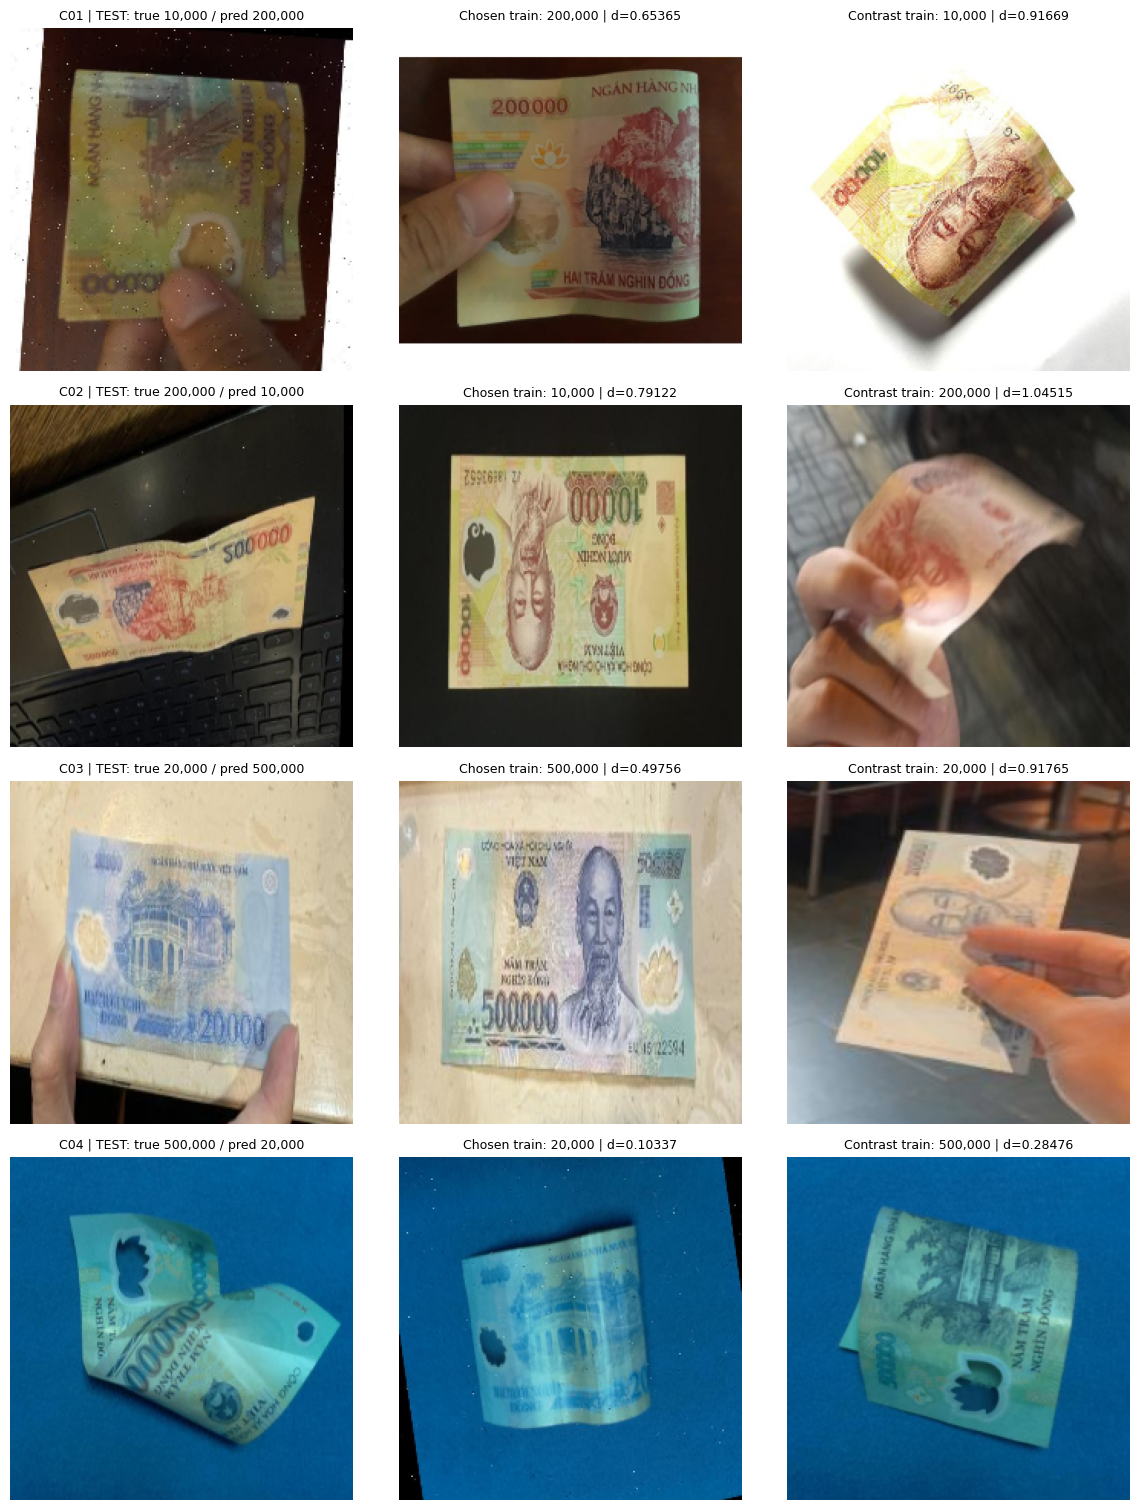

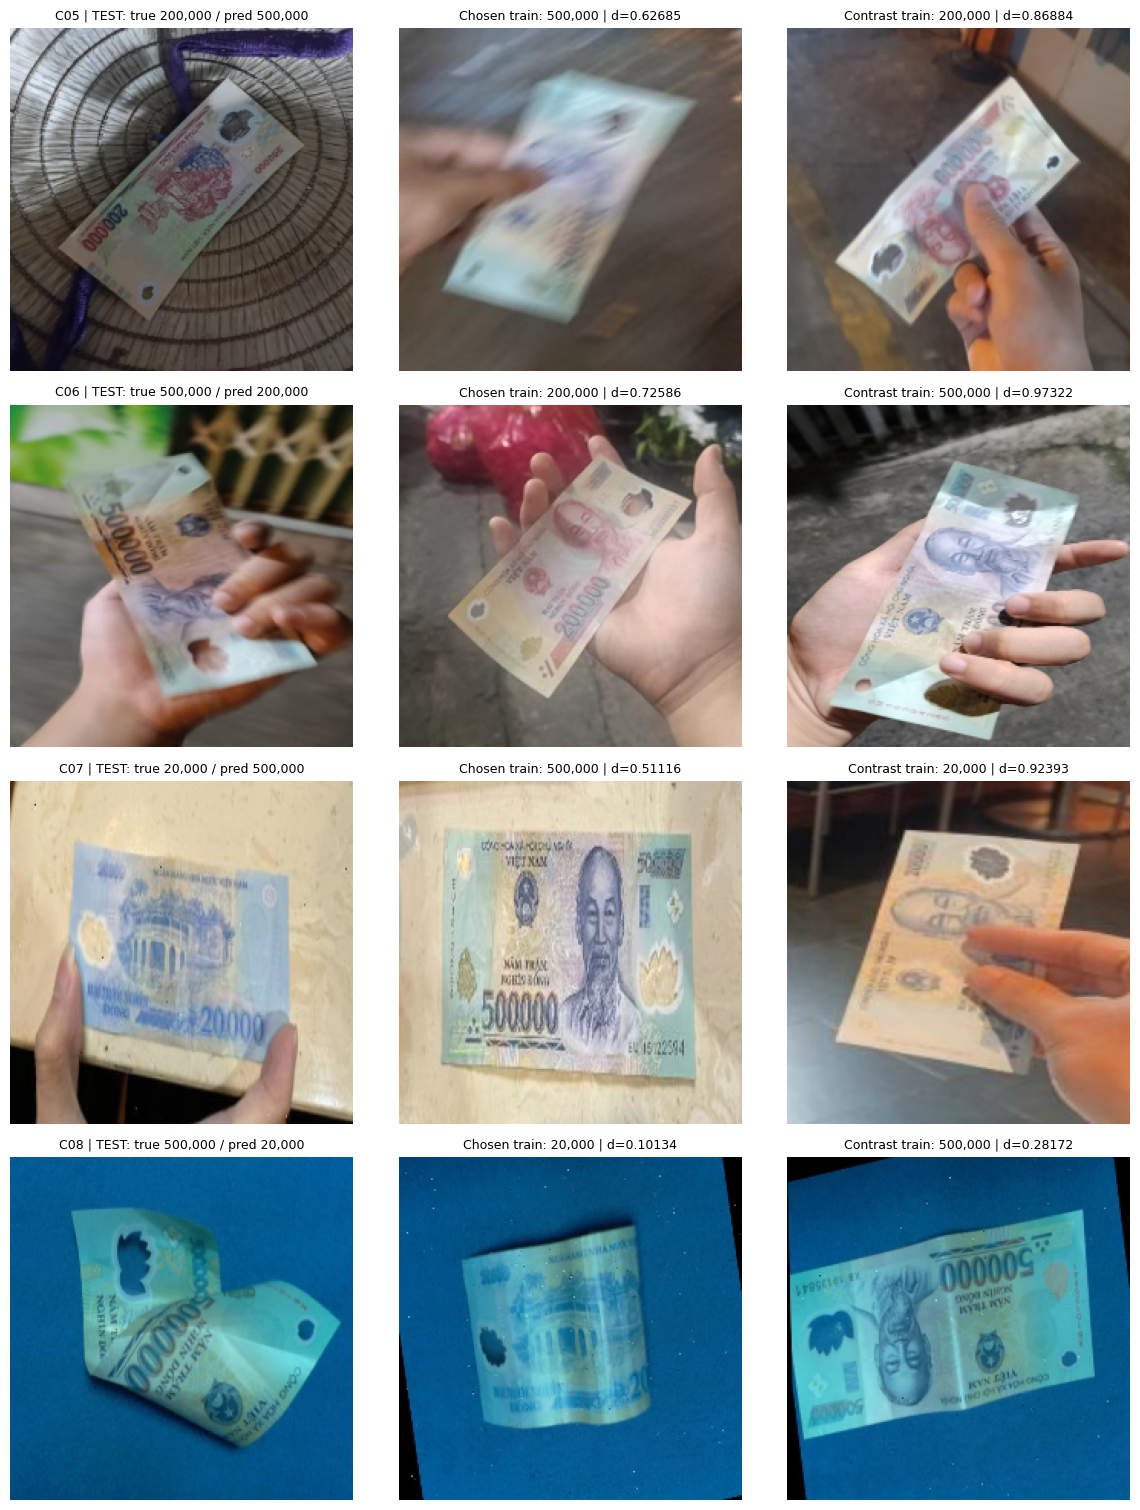

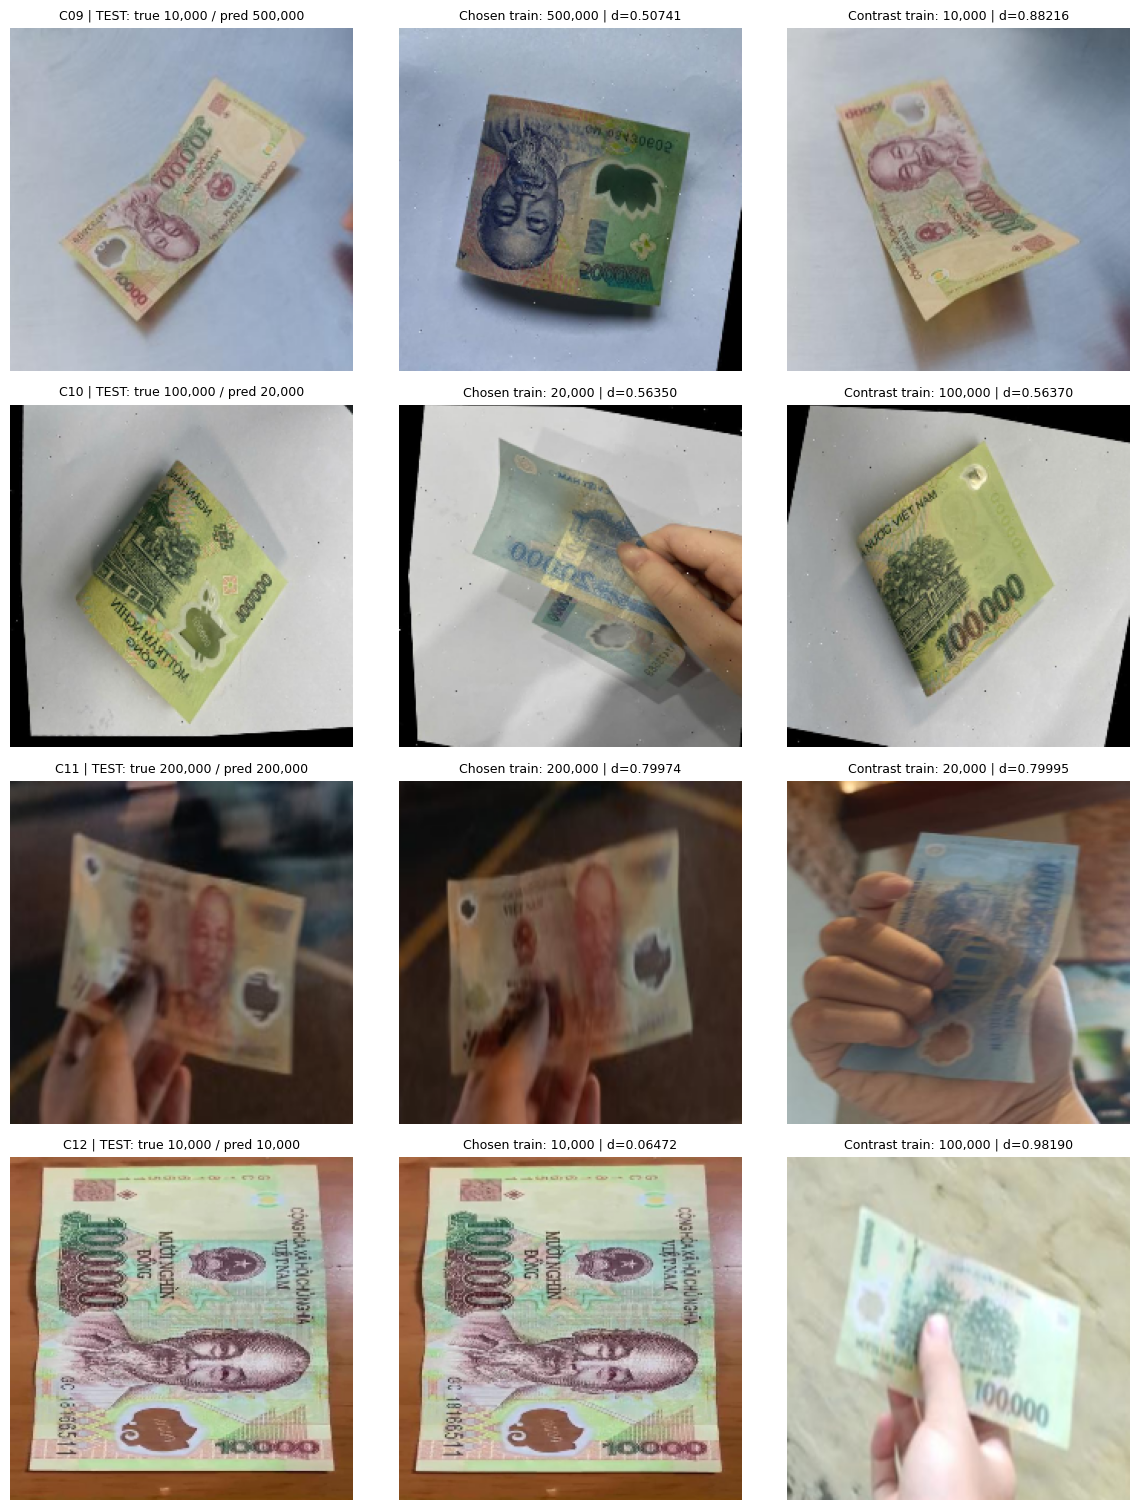

In [6]:
for start in range(0, len(cases), 4):
    page = cases.iloc[start:start + 4]
    fig, axes = plt.subplots(len(page), 3, figsize=(12, 3.8 * len(page)), squeeze=False)
    for r, row in enumerate(page.itertuples()):
        contrast_index = row.other_train_index if row.correct else row.same_train_index
        contrast_distance = row.other_distance if row.correct else row.same_distance
        contrast_path = train_manifest.iloc[contrast_index]["relative_path"]
        paths = [row.relative_path, row.nearest_train_path, contrast_path]
        titles = [
            f"{row.case_id} | TEST: true {row.y_true_vnd:,} / pred {row.y_pred_vnd:,}",
            f"Chosen train: {y_train[row.nearest_train_index]:,} | d={row.nearest_distance:.5f}",
            f"Contrast train: {y_train[contrast_index]:,} | d={contrast_distance:.5f}",
        ]
        for c in range(3):
            axes[r, c].imshow(read_rgb224(DATA_ROOT / paths[c]))
            axes[r, c].set_title(titles[c], fontsize=9)
            axes[r, c].axis("off")
    plt.tight_layout()
    fig.savefig(output_dir / f"cases_page_{start // 4 + 1:02d}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 6. Đối chiếu phân bố màu ở ba trường hợp

Dùng hai lỗi đầu và một ảnh đúng. Cộng histogram 3D theo hai trục để vẽ riêng phân bố H, S, V; chia tổng cho 1 giúp đọc tỷ lệ bin. Ba đường tương ứng query, train được chọn và train đối chiếu.

**Giới hạn:** đây là phân bố biên để minh họa, không phải 1.728 chiều mà KNN so sánh. Hai histogram có phân bố biên gần nhau vẫn có thể khác phân bố kết hợp. Chỉ khoảng cách trên vector 3D đã L2 ở mục trước trực tiếp giải thích quyết định. Không dùng các đường này để khẳng định nền/ánh sáng là nguyên nhân đã chứng minh.

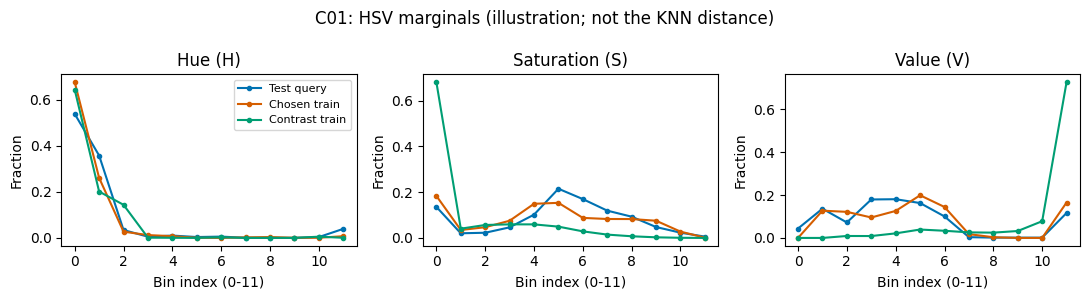

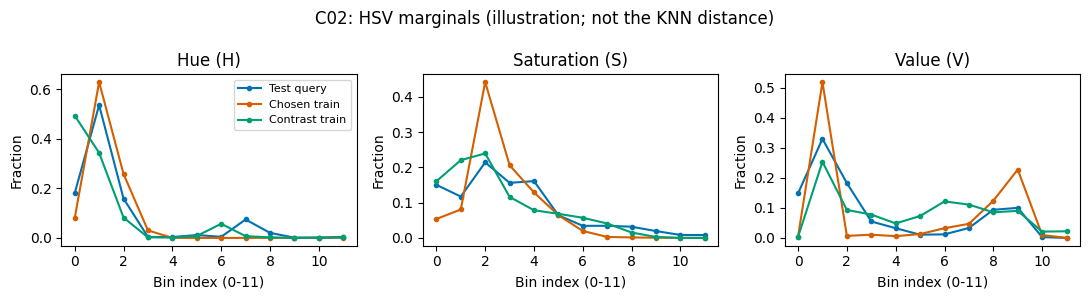

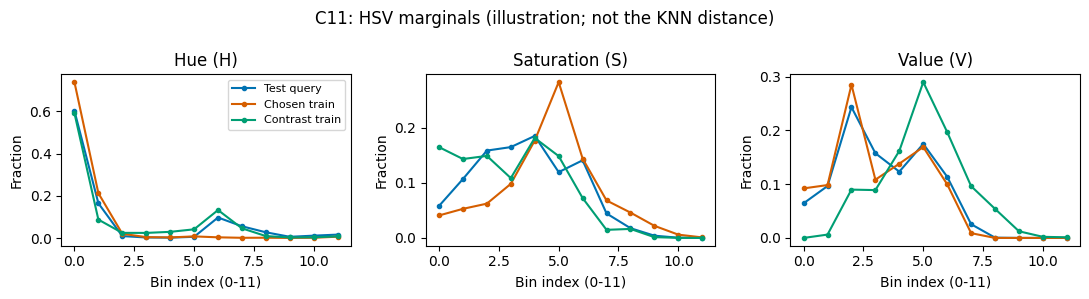

In [7]:
hist_cases = pd.concat([
    cases.loc[~cases["correct"]].head(2), cases.loc[cases["correct"]].head(1)
])
for row in hist_cases.itertuples():
    contrast_index = row.other_train_index if row.correct else row.same_train_index
    vectors = [X_test[row.test_index], X_train[row.nearest_train_index], X_train[contrast_index]]
    names = ["Test query", "Chosen train", "Contrast train"]
    colors = ["#0072B2", "#D55E00", "#009E73"]
    fig, axes = plt.subplots(1, 3, figsize=(11, 3))
    for vector, name, color in zip(vectors, names, colors):
        cube = vector.reshape(12, 12, 12)
        for channel, ax in enumerate(axes):
            other_axes = tuple(i for i in range(3) if i != channel)
            marginal = cube.sum(axis=other_axes)
            marginal = marginal / marginal.sum()
            ax.plot(range(12), marginal, label=name, color=color, marker=".")
            ax.set_title(["Hue (H)", "Saturation (S)", "Value (V)"][channel])
            ax.set_xlabel("Bin index (0-11)")
            ax.set_ylabel("Fraction")
    axes[0].legend(fontsize=8)
    fig.suptitle(f"{row.case_id}: HSV marginals (illustration; not the KNN distance)")
    plt.tight_layout()
    fig.savefig(output_dir / f"hsv_marginals_{row.case_id}.png", dpi=300, bbox_inches="tight")
    fig.savefig(output_dir / f"hsv_marginals_{row.case_id}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 7. Ghi chú thị giác và ranh giới kết luận

File ghi chú giữ riêng **quan sát**, **giả thuyết** và **điều chưa xác minh**. Không tự điền nguyên nhân bằng code. Sau khi chạy, người dùng/Codex xem hình rồi mới viết nhận xét cụ thể.

Gợi ý xem: chữ số có đọc được không; nền chiếm nhiều không; màu bị đổi do ánh sáng không; tờ tiền có bị gấp/che không; train được chọn giống query ở điểm nào. Các đặc điểm này chưa được gán nhãn cho toàn test, nên không báo tỷ lệ “bao nhiêu phần trăm lỗi do nền”.

HSV histogram không giữ bố cục hay đọc chữ số. Đó là giới hạn của biểu diễn; một ảnh rõ bị sai không tự chứng minh rằng chỉ riêng thiếu thông tin chữ số đã gây ra lỗi đó.

In [8]:
notes_file = output_dir / "visual_review_notes.csv"
if not notes_file.exists():
    notes = cases[["case_id", "relative_path", "selection_reason"]].copy()
    notes["observation"] = ""
    notes["hypothesis"] = ""
    notes["not_verified"] = ""
    notes.to_csv(notes_file, index=False)
else:
    print("Giữ nguyên ghi chú thị giác đã có:", notes_file)

source_files = [config_file, TEST_DIR / "X_test.npy", TEST_DIR / "predictions_test.csv",
                TEST_DIR / "test_manifest.csv", TEST_DIR / "metrics_test.json",
                PROJECT_ROOT / "src" / "preprocessing.py"]
record = {
    "feature": config["feature_id"], "knn": config["knn"],
    "n_test": len(analysis), "n_errors": int((~analysis["correct"]).sum()),
    "n_selected_cases": len(cases),
    "neighbor_labels_match_saved_predictions": True,
    "sha256": {p.relative_to(PROJECT_ROOT).as_posix(): file_hash(p) for p in source_files},
    "selection": "3 frequent pairs both directions; 3 largest-total-gap directions; 1 boundary error; 2 correct controls; no duplicate query",
    "visual_causes_verified": False,
    "test_used_for_retuning": False,
}
(output_dir / "analysis_record.json").write_text(json.dumps(record, indent=2), encoding="utf-8")
print("Đầu ra:", output_dir)
print("Xem hình trước, rồi bổ sung nhận xét có bằng chứng. Không tự thay cấu hình theo lỗi test.")

Đầu ra: C:\CS231\src\KNN\results_224\error_analysis
Xem hình trước, rồi bổ sung nhận xét có bằng chứng. Không tự thay cấu hình theo lỗi test.


## Sau khi chạy

Gửi kết quả để kiểm tra khoảng cách, hàng xóm và xem ảnh. Báo cáo cuối chỉ cần một bảng ngắn và khoảng hai hình ghép tiêu biểu từ các trang đã xuất; các trường hợp còn lại là evidence bổ sung. Chưa kết luận nguyên nhân thị giác khi chưa đọc ảnh.

Chạy lại sẽ ghi đè bảng/hình cùng tên trong `error_analysis`, nhưng giữ nguyên file ghi chú đã có. Không thay DATA, kết quả test, cấu hình khóa hoặc Git. Nếu thay quy tắc chọn ví dụ sau khi đã ghi chú, cần đối chiếu lại đường dẫn trong file ghi chú trước khi dùng.